# Project - Progress Report #4: Supervised and Unsupervised Learning
## Cybersecurity Vulnerability Severity Prediction Using Graph Machine Learning

**Class:** CS 4330 - Intro to Data Science

**Team:** Chesda Saroth, Tabitha Ondieki, Abdullahi Oyeniyi    
**Dataset:** Cleaned UCKG CVE sample (`../dataset/cve_clean.parquet`)  
**Deliverable:** `code/learning.ipynb`

We apply two **supervised** algorithms (K-Nearest Neighbors and Naive Bayes) to predict CVE severity, and one **unsupervised** algorithm (K-means clustering) to look for natural groups in the data. **Run All** from the repository's `code/` folder; the notebook uses the same cleaned CVE dataset as our earlier reports.

## 0. Load and prepare the data

We load the cleaned CVE records and keep rows with a valid severity label. The CVSS vector (for example `AV:N/AC:L/Au:N/C:P/I:P/A:P`) is split into one column per metric, such as attack vector (`AV`) and confidentiality impact (`C`). We keep the free-text `description` separately because Naive Bayes will use it.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, ConfusionMatrixDisplay,
                             silhouette_score, adjusted_rand_score)

SEED = 42
df = pd.read_parquet("../dataset/cve_clean.parquet")
df["description"] = df["description"].fillna("").astype(str)
df = df[df["description"].str.strip() != ""].copy()
df["severity"] = df["severity"].astype(str).str.upper().str.strip()
df = df[df["severity"].isin(["LOW", "MEDIUM", "HIGH", "CRITICAL"])].reset_index(drop=True)

# Split "AV:N/AC:L/Au:N/..." into one column per CVSS metric
X_cvss = df["cvss_vector"].fillna("").apply(
    lambda s: dict(part.split(":", 1) for part in str(s).split("/") if ":" in part)
).apply(pd.Series).fillna("missing")

y = df["severity"]
text = df["description"]

print("Records:", len(df))
print("Severity counts:", y.value_counts().to_dict())
print("CVSS columns:", list(X_cvss.columns))
display(X_cvss.head())

Records: 909
Severity counts: {'MEDIUM': 504, 'HIGH': 322, 'LOW': 83}
CVSS columns: ['AV', 'AC', 'Au', 'C', 'I', 'A']


,AV,AC,Au,C,I,A
0,N,L,N,P,P,P
1,N,L,N,C,C,C
2,N,L,N,P,P,P
3,L,L,N,P,P,P
4,N,L,N,N,P,N


**Interpretation:** The dataset has 909 CVE records: 504 Medium (55.4%), 322 High (35.4%) and 83 Low (9.1%), with no Critical examples. The CVSS vector splits into six metrics (AV, AC, Au, C, I, A). The classes are imbalanced: a model that always guessed Medium would be right about 55% of the time, so any useful model has to beat that baseline.

## 1. Supervised learning: K-Nearest Neighbors (KNN)

**What we intend to do.** KNN classifies a CVE by looking at the *k* most similar CVEs in the training data and taking a majority vote of their severity labels. Our features are the CVSS metrics, turned into 0/1 columns with `OneHotEncoder`.

We hold back a stratified 20% test set. We then choose *k* using 5-fold cross-validation on the **training data only**, so the test set stays unseen until the final score. We compare against a **majority-class baseline** (always guessing the biggest class). We also report balanced accuracy and macro-F1, because accuracy alone can hide poor results on the small LOW class.

Best k from cross-validation: 1


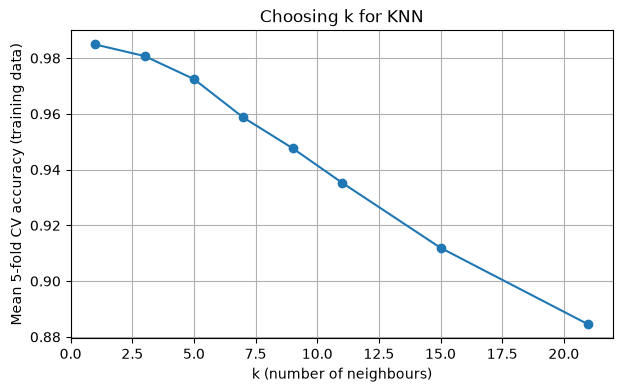

Majority-class baseline accuracy: 0.555
KNN test accuracy         : 0.989
KNN balanced accuracy     : 0.961
KNN macro-F1              : 0.976

              precision    recall  f1-score   support

        HIGH       1.00      1.00      1.00        64
         LOW       1.00      0.88      0.94        17
      MEDIUM       0.98      1.00      0.99       101

    accuracy                           0.99       182
   macro avg       0.99      0.96      0.98       182
weighted avg       0.99      0.99      0.99       182



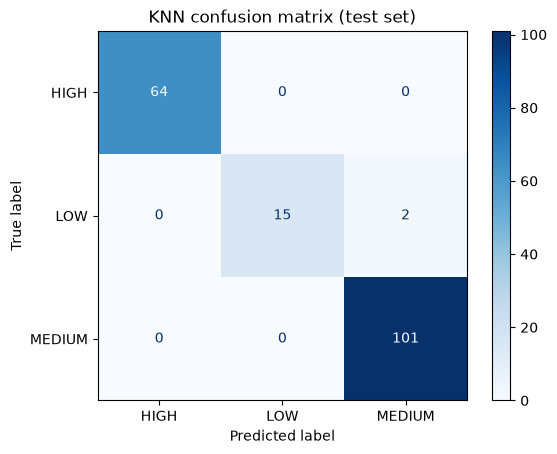

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X_cvss, y, test_size=0.2, random_state=SEED, stratify=y
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
k_values = [1, 3, 5, 7, 9, 11, 15, 21]
cv_scores = []
for k in k_values:
    knn = make_pipeline(OneHotEncoder(handle_unknown="ignore"),
                        KNeighborsClassifier(n_neighbors=k))
    cv_scores.append(cross_val_score(knn, X_train, y_train, cv=cv, scoring="accuracy").mean())

best_k = k_values[int(np.argmax(cv_scores))]
print("Best k from cross-validation:", best_k)

plt.figure(figsize=(7, 4))
plt.plot(k_values, cv_scores, marker="o")
plt.xlabel("k (number of neighbours)")
plt.ylabel("Mean 5-fold CV accuracy (training data)")
plt.title("Choosing k for KNN")
plt.grid(True)
plt.show()

knn_model = make_pipeline(OneHotEncoder(handle_unknown="ignore"),
                          KNeighborsClassifier(n_neighbors=best_k))
knn_model.fit(X_train, y_train)
knn_pred = knn_model.predict(X_test)

baseline = y_test.value_counts(normalize=True).max()
knn_acc = accuracy_score(y_test, knn_pred)
knn_bal = balanced_accuracy_score(y_test, knn_pred)
knn_f1 = f1_score(y_test, knn_pred, average="macro", zero_division=0)

print(f"Majority-class baseline accuracy: {baseline:.3f}")
print(f"KNN test accuracy         : {knn_acc:.3f}")
print(f"KNN balanced accuracy     : {knn_bal:.3f}")
print(f"KNN macro-F1              : {knn_f1:.3f}")
print()
print(classification_report(y_test, knn_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, knn_pred, cmap="Blues")
plt.title("KNN confusion matrix (test set)")
plt.show()

**Interpretation:** Cross-validation chose k = 1, and accuracy fell steadily as k grew, from about 0.985 at k = 1 to about 0.885 at k = 21. On the test set KNN reached 0.989 accuracy, 0.961 balanced accuracy and 0.976 macro-F1, far above the 0.555 baseline. All 64 High and all 101 Medium CVEs were classified correctly; the only mistakes were 2 of 17 Low CVEs predicted as Medium (Low recall 0.88). This high score is partly built into the problem: CVSS metrics are the inputs used to calculate severity, and many CVEs share an identical vector, so a 1-nearest-neighbor model is largely looking up the severity of a matching vector. It shows the method works, but not that severity can be predicted from independent information.

## 2. Supervised learning: Naive Bayes on the vulnerability text

**What we intend to do.** KNN above used the structured CVSS fields. Here we ask a harder and more independent question: can the **description text alone** predict severity? We convert each description into TF-IDF word weights (`TfidfVectorizer`, English stop words removed, words must appear in at least 2 descriptions) and train `MultinomialNB`, which learns how likely each word is within each severity class.

We use the **same stratified train/test split** as KNN, so both models are graded on exactly the same test CVEs. We also print the words each class relies on most, to see what the model learned.

Majority-class baseline accuracy: 0.555
Naive Bayes test accuracy : 0.582
Naive Bayes balanced acc. : 0.412
Naive Bayes macro-F1      : 0.412

              precision    recall  f1-score   support

        HIGH       0.53      0.38      0.44        64
         LOW       1.00      0.06      0.11        17
      MEDIUM       0.60      0.80      0.68       101

    accuracy                           0.58       182
   macro avg       0.71      0.41      0.41       182
weighted avg       0.61      0.58      0.54       182



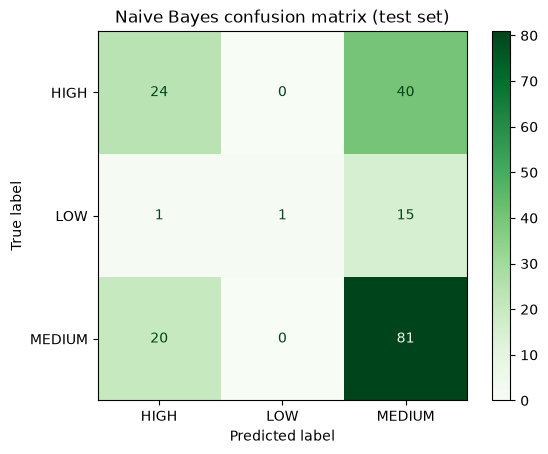

Top words per severity class:
  HIGH   : remote, allows, attackers, execute, php, arbitrary, code, en
  LOW    : local, users, files, file, en, allows, allow, lock
  MEDIUM : allows, remote, attackers, en, una, service, cause, la


In [3]:
Xt_train, Xt_test, yt_train, yt_test = train_test_split(
    text, y, test_size=0.2, random_state=SEED, stratify=y
)

nb_model = make_pipeline(
    TfidfVectorizer(stop_words="english", min_df=2, max_features=5000),
    MultinomialNB(alpha=0.5)
)
nb_model.fit(Xt_train, yt_train)
nb_pred = nb_model.predict(Xt_test)

nb_acc = accuracy_score(yt_test, nb_pred)
nb_bal = balanced_accuracy_score(yt_test, nb_pred)
nb_f1 = f1_score(yt_test, nb_pred, average="macro", zero_division=0)

print(f"Majority-class baseline accuracy: {baseline:.3f}")
print(f"Naive Bayes test accuracy : {nb_acc:.3f}")
print(f"Naive Bayes balanced acc. : {nb_bal:.3f}")
print(f"Naive Bayes macro-F1      : {nb_f1:.3f}")
print()
print(classification_report(yt_test, nb_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(yt_test, nb_pred, cmap="Greens")
plt.title("Naive Bayes confusion matrix (test set)")
plt.show()

# Which words does each class rely on most?
vectorizer = nb_model.named_steps["tfidfvectorizer"]
nb = nb_model.named_steps["multinomialnb"]
words = np.array(vectorizer.get_feature_names_out())
print("Top words per severity class:")
for i, cls in enumerate(nb.classes_):
    top = words[np.argsort(nb.feature_log_prob_[i])[-8:][::-1]]
    print(f"  {cls:<7}: {', '.join(top)}")

**Interpretation:** Naive Bayes on the description text alone reached 0.582 accuracy, only slightly above the 0.555 baseline, and its balanced accuracy and macro-F1 were both 0.412. This is much worse than KNN, which makes sense because the text gives only indirect clues about severity while the CVSS metrics define it. The model leans heavily toward Medium: it labeled only 1 of 17 Low CVEs correctly and only 24 of 64 High CVEs (40 High CVEs were called Medium), so Low is the hardest class. Some top words are meaningful (execute, arbitrary and code for High; local for Low), but many are generic and appear in several classes (allows, attackers, remote). Spanish words such as en, una and la also appear because some descriptions are in Spanish and we only removed English stop words.

### Supervised summary

We put both models side by side on the same test set so the comparison is fair.

,Model,Accuracy,Balanced accuracy,Macro-F1
0,Majority-class baseline,0.555,NaN,NaN
1,"KNN (CVSS metrics, k=1)",0.989,0.961,0.976
2,Naive Bayes (description text),0.582,0.412,0.412


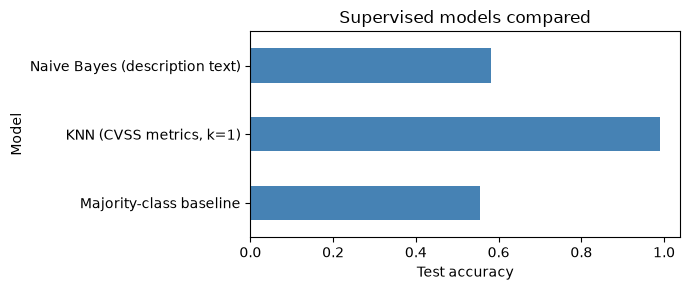

In [4]:
supervised_results = pd.DataFrame({
    "Model": ["Majority-class baseline", f"KNN (CVSS metrics, k={best_k})", "Naive Bayes (description text)"],
    "Accuracy": [baseline, knn_acc, nb_acc],
    "Balanced accuracy": [np.nan, knn_bal, nb_bal],
    "Macro-F1": [np.nan, knn_f1, nb_f1],
})
display(supervised_results.round(3))

supervised_results.set_index("Model")["Accuracy"].plot(kind="barh", figsize=(7, 3), color="steelblue")
plt.xlabel("Test accuracy")
plt.title("Supervised models compared")
plt.tight_layout()
plt.show()

**Interpretation:** KNN scored 0.989 accuracy compared with 0.582 for Naive Bayes and 0.555 for the baseline. KNN is far more accurate, but its inputs define severity, so its score is partly circular. Naive Bayes is a fairer test of whether independent information (the text) predicts severity, and its weak result (balanced accuracy 0.412) shows that text alone is not enough with only 909 records. Accuracy alone can also mislead: Naive Bayes looks slightly better than the baseline, but its balanced accuracy shows it almost ignores the Low class.

## 3. Unsupervised learning: K-means clustering

**What we intend to do.** K-means groups CVEs into *k* clusters **without ever seeing the severity labels**. We cluster on the one-hot CVSS metrics. First we try k = 2 to 8 and use two guides to pick a good k:

- **Elbow plot (inertia):** how tightly packed the clusters are. We look for the bend where adding clusters stops helping much.
- **Silhouette score:** from -1 to 1, how well each point sits in its own cluster versus the next one. Higher is better.

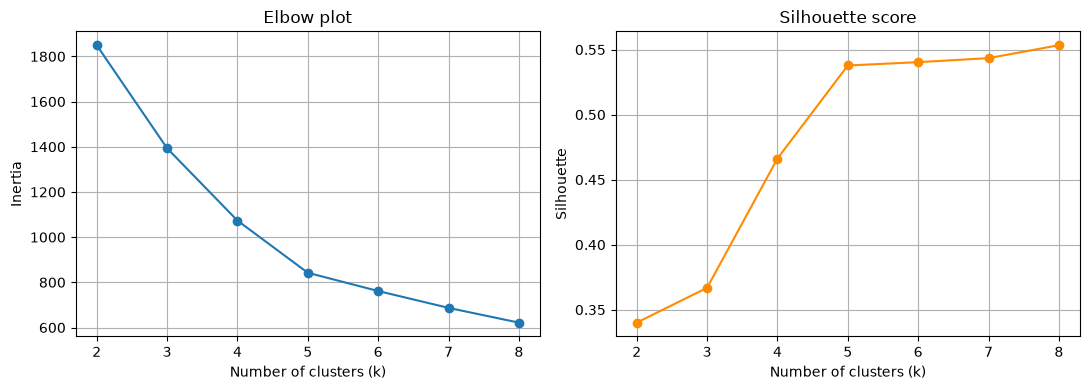

Silhouette by k: {2: 0.34, 3: 0.367, 4: 0.466, 5: 0.538, 6: 0.54, 7: 0.543, 8: 0.553}


In [5]:
X_enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit_transform(X_cvss)

ks = list(range(2, 9))
inertias, silhouettes = [], []
for k in ks:
    km_try = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_enc)
    inertias.append(km_try.inertia_)
    silhouettes.append(silhouette_score(X_enc, km_try.labels_))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(ks, inertias, marker="o")
axes[0].set(title="Elbow plot", xlabel="Number of clusters (k)", ylabel="Inertia")
axes[1].plot(ks, silhouettes, marker="o", color="darkorange")
axes[1].set(title="Silhouette score", xlabel="Number of clusters (k)", ylabel="Silhouette")
for ax in axes:
    ax.grid(True)
plt.tight_layout()
plt.show()

print("Silhouette by k:", {k: round(s, 3) for k, s in zip(ks, silhouettes)})

**Interpretation:** The elbow plot drops sharply until about k = 4 or 5 (inertia falls from about 1850 at k = 2 to about 840 at k = 5) and then flattens. The silhouette score rises from 0.340 at k = 2 to 0.538 at k = 5 and then barely changes (0.553 at k = 8). The two guides agree that around k = 5 is where extra clusters stop helping much. We used k = 3 for the next step so the clusters can be compared directly with the three severity classes (Low, Medium, High), although k = 5 would fit the structure of the data better.

### Fit K-means and check whether the clusters match severity

Now we fit K-means with the chosen number of clusters. Because the algorithm never saw the severity labels, we can use them afterwards as a check: a table of cluster vs. severity, and the **Adjusted Rand Index** (about 0 means the clusters match severity no better than chance; 1 means a perfect match). A 2D PCA projection lets us see the clusters.

Silhouette score (k=3): 0.367
Adjusted Rand Index vs severity: 0.297

Cluster vs severity (counts):


severity,HIGH,LOW,MEDIUM
cluster,,,
0,135,0,23
1,18,80,369
2,169,3,112


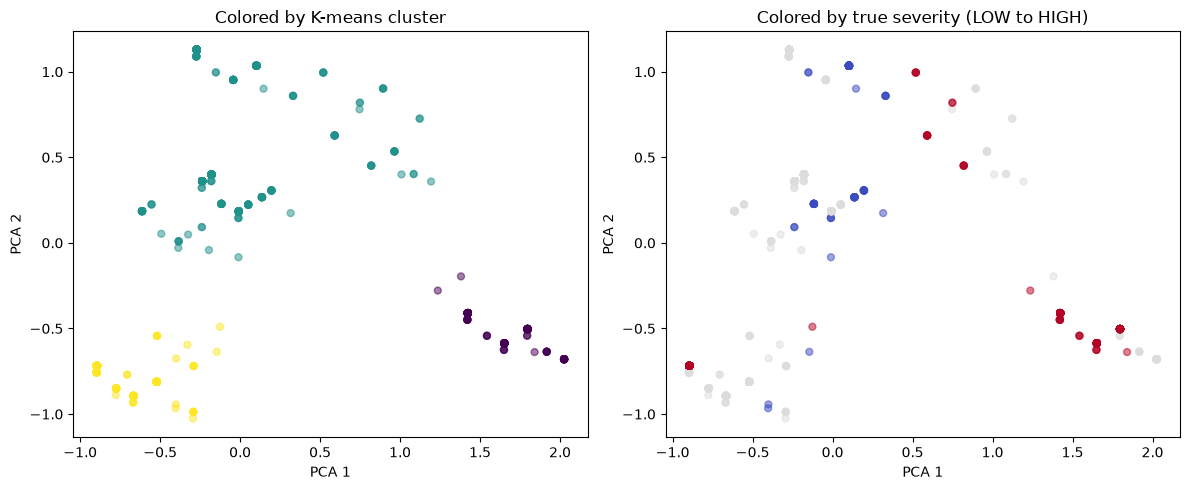

In [6]:
N_CLUSTERS = 3   # change this to the k you chose from the plots above

km = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=SEED).fit(X_enc)
clusters = km.labels_

print(f"Silhouette score (k={N_CLUSTERS}): {silhouette_score(X_enc, clusters):.3f}")
print(f"Adjusted Rand Index vs severity: {adjusted_rand_score(y, clusters):.3f}")
print()
print("Cluster vs severity (counts):")
display(pd.crosstab(clusters, y, rownames=["cluster"], colnames=["severity"]))

# 2D view of the same data (PCA only squeezes it into 2 dimensions for plotting)
coords = PCA(n_components=2, random_state=SEED).fit_transform(X_enc)
severity_code = y.map({"LOW": 0, "MEDIUM": 1, "HIGH": 2, "CRITICAL": 3})

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(coords[:, 0], coords[:, 1], c=clusters, cmap="viridis", alpha=0.5, s=25)
axes[0].set(title="Colored by K-means cluster", xlabel="PCA 1", ylabel="PCA 2")
axes[1].scatter(coords[:, 0], coords[:, 1], c=severity_code, cmap="coolwarm", alpha=0.5, s=25)
axes[1].set(title="Colored by true severity (LOW to HIGH)", xlabel="PCA 1", ylabel="PCA 2")
plt.tight_layout()
plt.show()

**Interpretation:** With k = 3, the silhouette score was 0.367 and the Adjusted Rand Index was 0.297, so the clusters match severity better than chance (0) but are far from a perfect match (1). Cluster 0 (158 CVEs) is mostly High (135, about 85%). Cluster 1 (467 CVEs) is mostly Medium (369) and contains 80 of the 83 Low CVEs. Cluster 2 (284 CVEs) is a mix of High (169) and Medium (112). In the PCA plots the cluster colors and severity colors partly line up, with many red High points toward the right, but not exactly. Many CVEs share the same CVSS vector, so many points sit on top of each other and the plots show far fewer points than the 909 records. K-means found structure without seeing any labels, which suggests CVSS metrics group vulnerabilities in a way related to severity, but the clusters are not simply the severity classes.

## 4. Conclusion

In this report we applied KNN and Naive Bayes to predict CVE severity and K-means to look for natural groups. KNN on the CVSS metrics performed best (0.989 accuracy with k = 1), but this is partly because CVSS metrics are used to define severity, so it shows the method works rather than proving independent prediction. Naive Bayes on description text alone was only slightly better than always guessing Medium (0.582 vs 0.555) and almost never predicted Low. K-means with k = 3 produced clusters that partly matched severity (ARI = 0.297): one mostly High, one mostly Medium that held nearly all Low cases, and one mixed. Our data has limits: only 909 records, no Critical examples, a small Low class (83) and some descriptions in Spanish. We learned that accuracy must be compared with a baseline and read alongside balanced accuracy and macro-F1, that cross-validation should be used to choose settings such as k, and that unsupervised results need an outside check such as the Adjusted Rand Index.